<h1>Description:</h1>

Breast cancer is the most common cancer amongst women in the world. It accounts for 25% of all cancer cases, and affected over 2.1 Million people in 2015 alone. It starts when cells in the breast begin to grow out of control. These cells usually form tumors that can be seen via X-ray or felt as lumps in the breast area.

The key challenge against its detection is how to classify tumors into malignant (cancerous) or benign(non-cancerous). We ask you to complete the analysis of classifying these tumors using machine learning (with logistic regression) and the Breast Cancer Wisconsin (Diagnostic) Dataset.

<h2>Acknowledgements:</h2>
This dataset has been referred from Kaggle.

<h2>Objective:</h2>
Understand the Dataset & cleanup (if required).
Build a classification model to predict whether a tumour is malignant or benign, and evaluate it with appropriate metrics.
Also fine-tune the hyperparameters & compare the evaluation metrics of various classification algorithms.

<h1>Step 1 Import libraries </h1>

In [1]:
# math        -> general maths functions
# numpy       -> number handling
# pandas      -> loading and working with the data table
# matplotlib  -> plotting
# seaborn     -> the correlation heatmap
# plotly      -> the interactive charts in Step 3
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

<h1> Step 2 Import the csv file </h1>

In [3]:
# read the breast cancer dataset and look at the first 5 rows
# 569 tumours; diagnosis is M (malignant) or B (benign)
df = pd.read_csv('data/breast-cancer.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<h1> Step 3.1 Visualise the dataset </h1>
Visualise a histogram to understand the split between the diagnosis (Malignant or Benign)

In [ ]:
# interactive bar chart: how many tumours of each diagnosis?
# colour separates malignant (M) from benign (B)
px.histogram(data_frame=df, x='diagnosis', color='diagnosis',color_discrete_sequence=['#76467E','#46A6DA'])

<h1> Step 3.2 Visualise the data set </h1>

In [ ]:
# histogram of tumour area, split by diagnosis -
# malignant tumours tend to sit further right (larger areas)
px.histogram(data_frame=df,x='area_mean',color='diagnosis',color_discrete_sequence=['#56445E','#7600DA'])

<h1> Step 3.3 Visualise the data set </h1>
Draw a scatter plot on symmetry_worst field and understand the spread of malignancy

In [ ]:
# scatter of symmetry_worst for every tumour, coloured by diagnosis -
# shows how well this single feature separates the two groups
px.scatter(data_frame=df,x='symmetry_worst',color='diagnosis',color_discrete_sequence=['#05445E','#75E6DA'])

<h1> Step 3.4 Visualise the data set </h1>
Draw a scatter plot on concavity_worst field and understand the spread of malignancy

In [ ]:
# same idea with concavity_worst - a clearer separation than symmetry
px.scatter(data_frame=df,x='concavity_worst',color='diagnosis',color_discrete_sequence=['#2200FE','#00F7DF'])

<h1> Step 4 Drop the redundant column </h1>

In [ ]:
# the id column identifies the patient but says nothing about the tumour - drop it
df.drop('id', axis=1, inplace=True)

<h1> Step 5 Encoding the label to 0/1 </h1>
The diagnosis column is 'M' or 'B', so lets convert this to 0/1. 0 is benign and 1 is malignant

In [ ]:
# turn the diagnosis text into numbers: the comparison gives True/False,
# and astype(int) converts that to 1 (malignant) / 0 (benign)
df['diagnosis'] = (df['diagnosis'] == 'M').astype(int) #encode the label into 1/0

<h1> Step 6.1 Compute Correlation </h1>
Compute pairwise correlation of columns, excluding NA/null values

In [ ]:
# correlation between every pair of columns
# (works because every column is now numeric)
corr = df.corr()

<h1> Step 6.2 Visualise the Heatmap </h1>


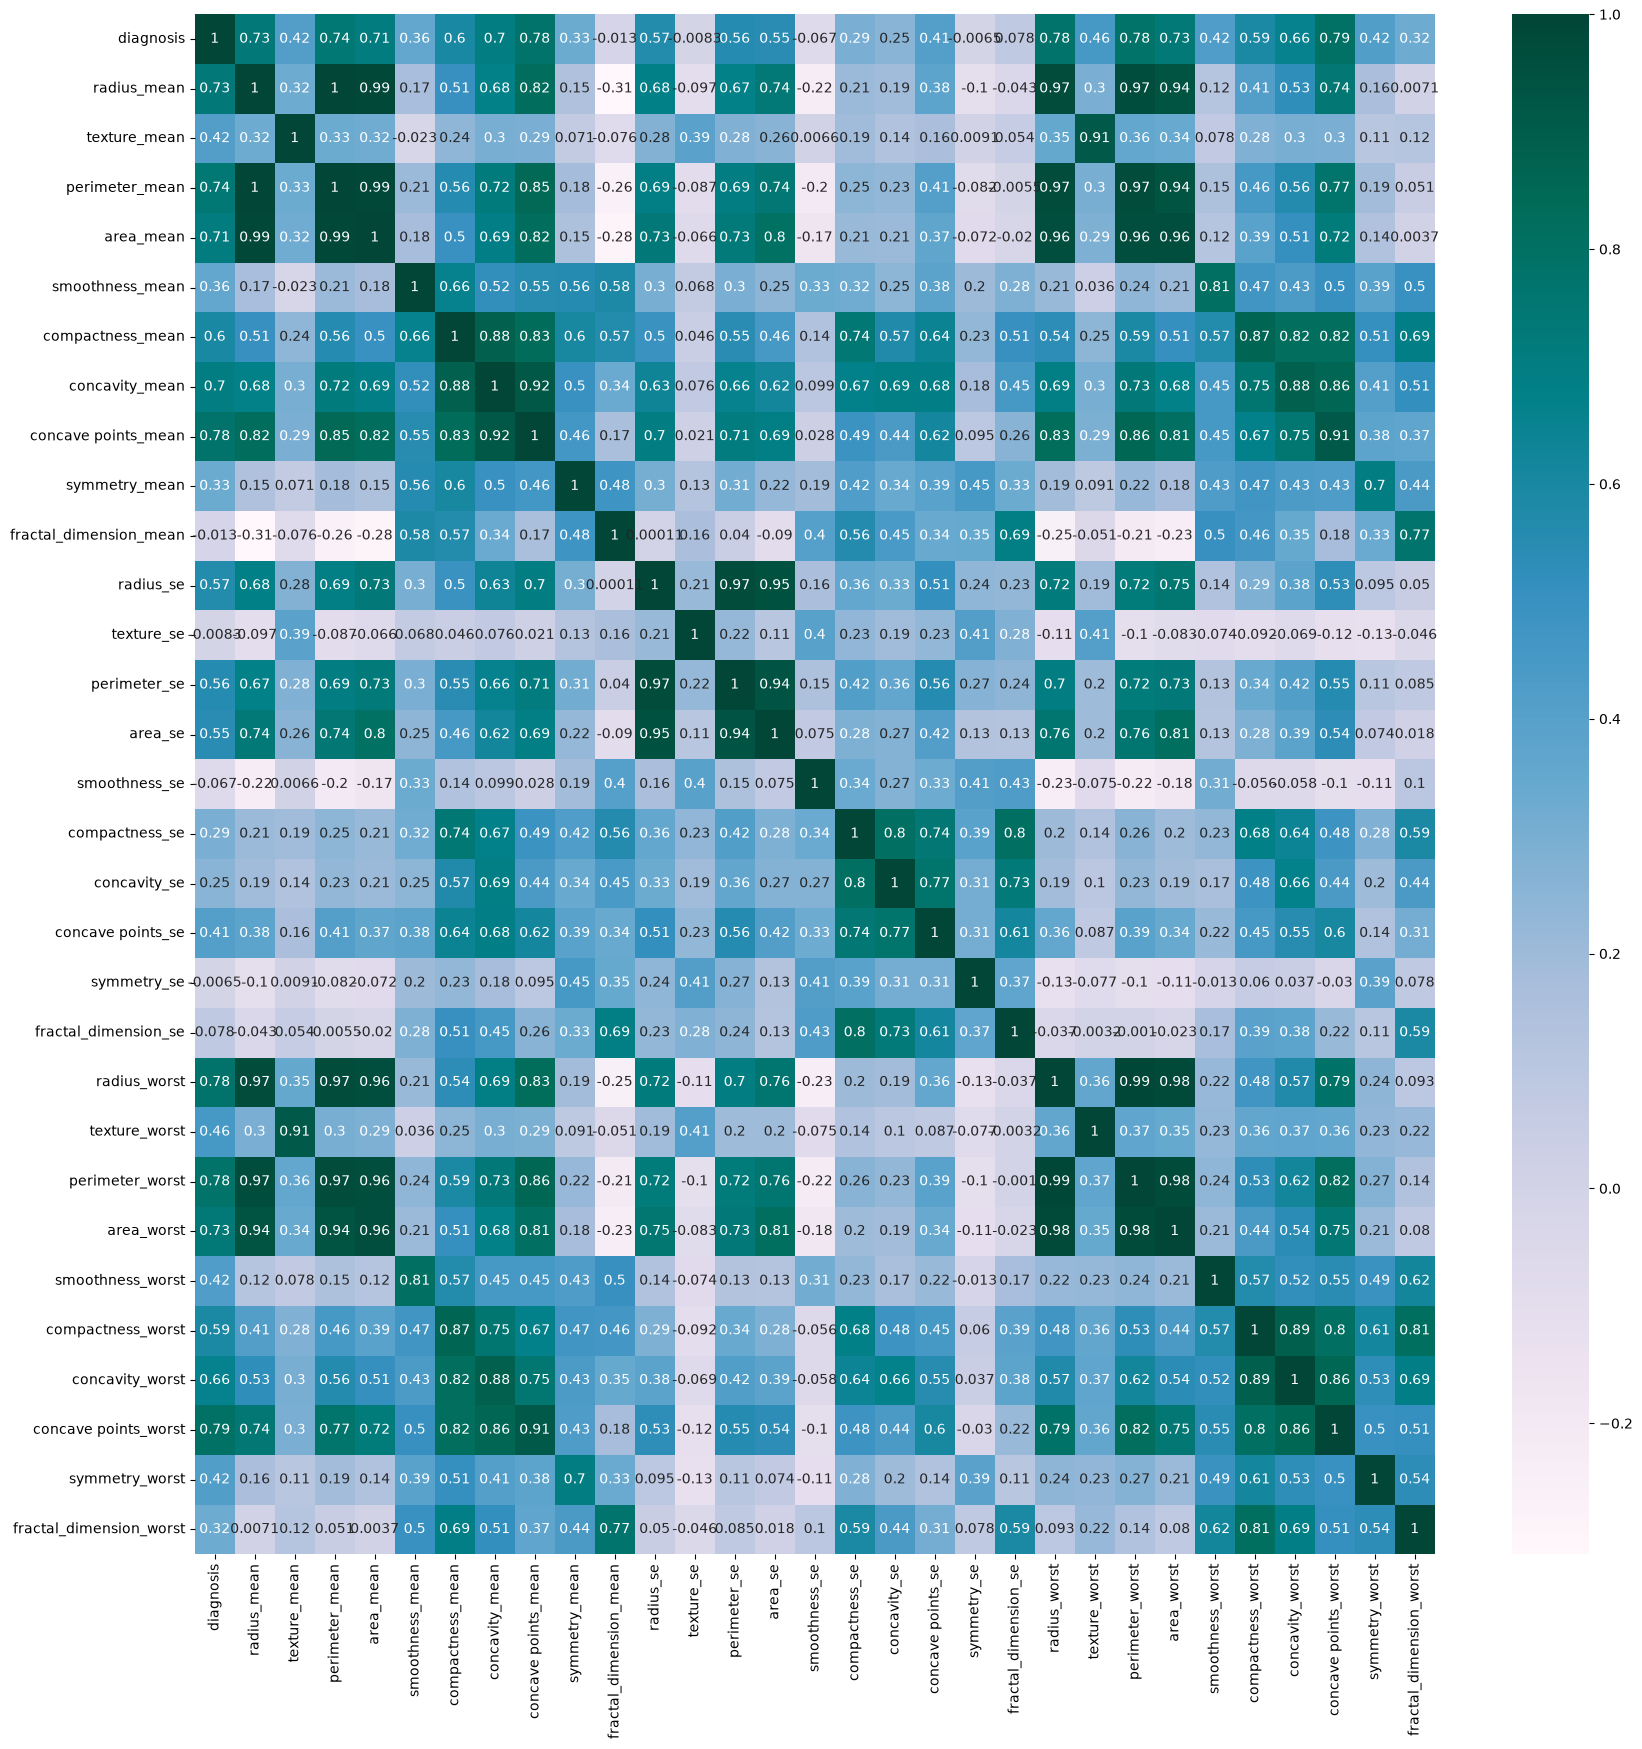

In [ ]:
# the full correlation matrix as a heatmap - 31 columns, so it is big;
# annot=True prints the value inside every square
plt.figure(figsize=(20,20))
sns.heatmap(corr, cmap='PuBuGn',annot=True)
plt.show()
plt.show()

<h1>Step 7 Select the columns </h1>
In this step get the correlated target variable and then select the correlated features with this target above 0.2. Get the names of these correlated features and get your data set ready by removing the target field.

In [ ]:
correlated_target = abs(corr["diagnosis"])                      # absolute correlation with the target
relevant_features = correlated_target[correlated_target > 0.2]  # select correlated features higher than 0.2
names = [index for index, value in relevant_features.items()]   # Get the names of the features
names.remove('diagnosis')                                       # drop the target itself from the results
print(names)                                                    # displaying the results




['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'radius_se', 'perimeter_se', 'area_se', 'compactness_se', 'concavity_se', 'concave points_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


<h1>Step 8 Select the columns for X and Y</h1>


In [ ]:
# X = the selected feature columns as a plain array
# y = the diagnosis (1 = malignant, 0 = benign) - what we want to predict
X = df[names].values
y = df['diagnosis'].values

<h1>Step 9 Split the dataset into training and testing data sets</h1>


In [ ]:
# split into training (80%) and test (20%) sets
# random_state=0 -> same split every run
# stratify=y     -> keeps the malignant/benign ratio the same in both sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

<h1>Step 10 Normalise the data</h1>


In [ ]:
# standardise the features: rescale each column to mean 0, standard deviation 1,
# so features measured in hundreds don't drown out features measured in decimals
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() 

# fit_transform on TRAIN: learn the mean and std, then rescale
X_train = scaler.fit_transform(X_train)

# transform only on TEST: reuse the means and stds learned from the training set
X_test = scaler.transform(X_test)

<h1>Step 11 Apply the Logistic Regression</h1>
In this step we apply the logistic regression from the sklearn library and fit the data of X_train and y_train

In [ ]:
# create the Logistic Regression model and fit it to the training data
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

<h1>Step 12 Confusion Matrix </h1>
In this step we evaluate the model on the test set. The confusion matrix shows the four possible outcomes — true and false positives and negatives — exactly as covered in our lesson.

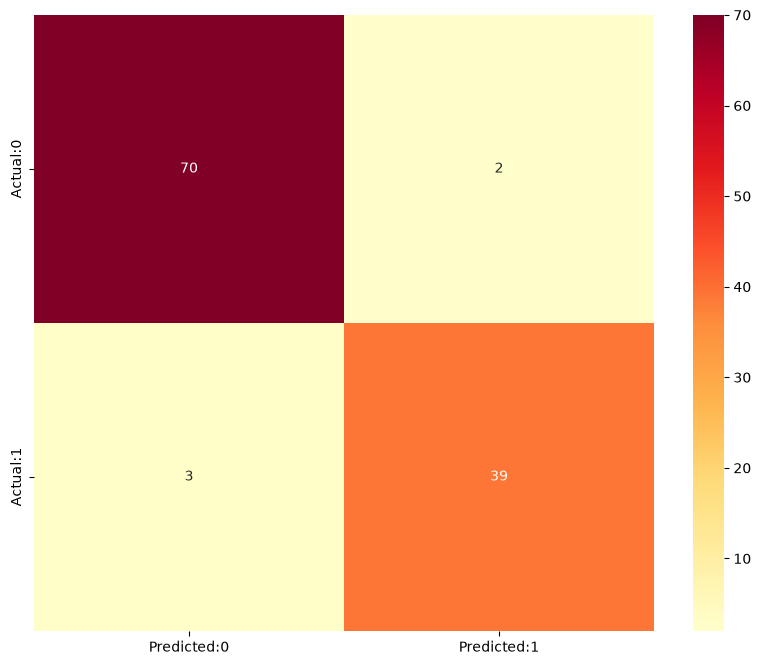

[[70  2]
 [ 3 39]]
Accuracy: 0.956140350877193


In [ ]:
# from sklearn.metrics import confusion_matrix, accuracy_score
# import sklearn

# y_pred = classifier.predict(X_test)
# sklearn.metrics.accuracy_score(y_test,y_pred)
# sklearn.metrics.accuracy_score(y_test,y_pred)
# cmatrix = confusion_matrix(y_test, y_pred)
# conf_matrix = pd.DataFrame(data=cmatrix, columns=['Predicted:0','Predicted:1'],index=['Actual:0','Actual:1'])
# plt.figure(figsize = (10,8))
# sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='YlOrRd')
# confusion_mat = confusion_matrix(y_test, y_pred)
# print(confusion_mat)
# accuracy_score(y_test, y_pred)

# Import the two evaluation tools we need from scikit-learn
from sklearn.metrics import confusion_matrix, accuracy_score

# Ask the trained model to predict a diagnosis (0 or 1) for every
# tumour in the test set - data it has never seen during training
y_pred = classifier.predict(X_test)

# Compare the model's predictions (y_pred) against the true answers (y_test).
# The result is a 2x2 grid counting the four possible outcomes:
#   [[true negatives,  false positives],
#    [false negatives, true positives]]
cmatrix = confusion_matrix(y_test, y_pred)

# Wrap the raw numbers in a labelled DataFrame so the heatmap
# shows meaningful row/column names instead of just 0 and 1.
# Rows = what the tumour actually was; columns = what the model said.
conf_matrix = pd.DataFrame(data=cmatrix,
                           columns=['Predicted:0', 'Predicted:1'],
                           index=['Actual:0', 'Actual:1'])

# Draw the confusion matrix as a heatmap.
# annot=True prints the count inside each cell; fmt='d' formats them as whole numbers
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='YlOrRd')
plt.show()

# Print the raw matrix as text, then the overall accuracy -
# the proportion of all 114 test tumours the model classified correctly.
# Remember from the course: accuracy alone is not enough for medical data,
# which is why the next step looks at precision and recall.
print(cmatrix)
print('Accuracy:', accuracy_score(y_test, y_pred))

<h1>Beyond accuracy</h1>

In a medical problem, accuracy is not enough — the two kinds of error have very different costs. Precision and recall, show how the model performs on the malignant class specifically.

In [ ]:
# per-class marking: precision (of those flagged, how many were right),
# recall (of the real cases, how many were caught), and their balance (f1)
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))

               precision    recall  f1-score   support

   Benign (0)       0.96      0.97      0.97        72
Malignant (1)       0.95      0.93      0.94        42

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



<h1>Step 13 Validate the data </h1>


In [ ]:
# instead of a hard 0/1 answer, ask the model HOW SURE it is:
# two probabilities per tumour (benign, malignant) that add up to 1
y_pred_prob = classifier.predict_proba(X_test)
y_pred_prob_df = pd.DataFrame(data=y_pred_prob, columns=['Probability of no Malignancy(0)','Probability of Malignancy (1)'])
y_pred_prob_df.head()


,Probability of no Malignancy(0),Probability of Malignancy (1)
0,0.999723,0.000277
1,0.985659,0.014341
2,0.795982,0.204018
3,0.988806,0.011194
4,0.999855,0.000145


<h1>What did we find?</h1>

The model scored 96% accuracy — but the confusion matrix tells the fuller story: of 42 malignant tumours in the test set, the model caught 39 and missed 3 (false negatives), while raising 2 false alarms. That's a recall of 0.93 for the malignant class. As the course's skin cancer example teaches, in medical screening the false negatives are the costly errors — which is why we judge this model on precision and recall, not accuracy alone. It also shows why results from a single train/test split should be treated with care: a different random split of this same data gives slightly different numbers, which is exactly the problem cross-validation is designed to smooth out.